In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



In [2]:

df = pd.read_csv('deliriumwatch_master.csv')
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nData types:\n", df.dtypes)

Shape: (57992, 31)

Columns: ['subject_id', 'stay_id', 'delirium_label', 'age', 'gender', 'first_careunit', 'icu_los_hours', 'avg_sofa', 'max_sofa', 'admission_sofa', 'hr_mean', 'hr_std', 'hr_min', 'hr_max', 'rr_mean', 'rr_std', 'spo2_mean', 'spo2_min', 'nibp_mean', 'nibp_min', 'abp_mean', 'propofol_total', 'midazolam_total', 'lorazepam_total', 'dexmedetomidine_total', 'fentanyl_total', 'unique_sedation_drugs', 'nid_score', 'night_day_ratio', 'night_interventions', 'day_interventions']

Data types:
 subject_id                 int64
stay_id                    int64
delirium_label             int64
age                        int64
gender                       str
first_careunit               str
icu_los_hours              int64
avg_sofa                 float64
max_sofa                   int64
admission_sofa             int64
hr_mean                  float64
hr_std                   float64
hr_min                   float64
hr_max                   float64
rr_mean                  float64


In [3]:

cols = [
    'subject_id',     
    'stay_id',           
    'icu_los_hours',  
    'night_interventions',
    'day_interventions'     
]

df_clean = df.drop(columns=cols)
print("Shape", df_clean.shape)
print("Remaining columns:", df_clean.columns.tolist())

Shape (57992, 26)
Remaining columns: ['delirium_label', 'age', 'gender', 'first_careunit', 'avg_sofa', 'max_sofa', 'admission_sofa', 'hr_mean', 'hr_std', 'hr_min', 'hr_max', 'rr_mean', 'rr_std', 'spo2_mean', 'spo2_min', 'nibp_mean', 'nibp_min', 'abp_mean', 'propofol_total', 'midazolam_total', 'lorazepam_total', 'dexmedetomidine_total', 'fentanyl_total', 'unique_sedation_drugs', 'nid_score', 'night_day_ratio']


In [4]:
# Missing value analysis
missing = df_clean.isnull().sum()
missing_pct = (missing / len(df_clean) * 100)

missing_df = pd.DataFrame({
    'missing_count': missing,
    'missing_pct': missing_pct
}).sort_values('missing_pct', ascending=False)

#shows columns that are missing
print(missing_df[missing_df['missing_count'] > 0])

           missing_count  missing_pct
abp_mean           33515    57.792454
nibp_mean            379     0.653538
nibp_min             379     0.653538
rr_std                45     0.077597
rr_mean               38     0.065526
spo2_mean              8     0.013795
spo2_min               8     0.013795
hr_std                 1     0.001724


In [5]:
# creates a flag BEFORE filling
df_clean['abp_measured'] = (
    df_clean['abp_mean'].notnull().astype(int)
)

# Fill abp_mean with 0 (no arterial line = 0 reading)
df_clean['abp_mean'] = df_clean['abp_mean'].fillna(0)

# missing values: filled with median
median_cols = [
    'nibp_mean', 'nibp_min', 
    'rr_std', 'rr_mean',
    'spo2_mean', 'spo2_min', 
    'hr_std'
]
for col in median_cols:
    median_val = df_clean[col].median()
    df_clean[col] = df_clean[col].fillna(median_val)
    print(f"{col}: filled with median {median_val:.2f}")
print("\nMissing after treatment:", 
      df_clean.isnull().sum().sum())

nibp_mean: filled with median 78.84
nibp_min: filled with median 58.00
rr_std: filled with median 4.09
rr_mean: filled with median 18.93
spo2_mean: filled with median 96.68
spo2_min: filled with median 90.00
hr_std: filled with median 9.48

Missing after treatment: 0


Class distribution:
No delirium (0): 36971 (63.8%)
Delirium    (1): 21021 (36.2%)
Ratio: 1:1.8


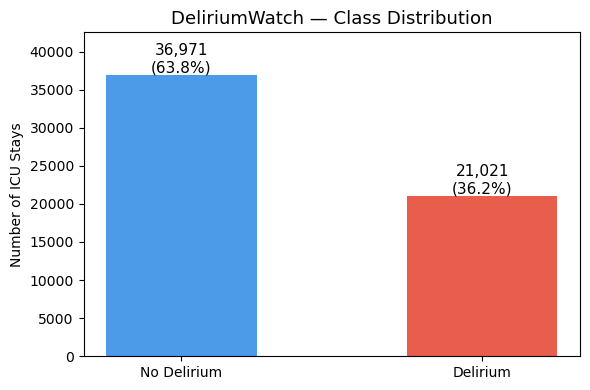

In [6]:
counts = df_clean['delirium_label'].value_counts()
pcts = df_clean['delirium_label'].value_counts(
    normalize=True
) * 100

print("Class distribution:")
print(f"No delirium (0): {counts[0]} ({pcts[0]:.1f}%)")
print(f"Delirium    (1): {counts[1]} ({pcts[1]:.1f}%)")
print(f"Ratio: 1:{counts[0]/counts[1]:.1f}")


fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(['No Delirium', 'Delirium'], 
               counts.values,
               color=['#4C9BE8', '#E85D4C'],
               width=0.5)

# Adds count
for bar, count, pct in zip(
    bars, counts.values, pcts.values
):
    ax.text(bar.get_x() + bar.get_width()/2, 
            bar.get_height() + 300,
            f'{count:,}\n({pct:.1f}%)',
            ha='center', fontsize=11)

ax.set_title('DeliriumWatch — Class Distribution', 
             fontsize=13)
ax.set_ylabel('Number of ICU Stays')
ax.set_ylim(0, max(counts.values) * 1.15)
plt.tight_layout()
plt.show()